# Assignment 2: The Bookstore Intelligence Mission
**Juan Abbas | Business Data and Text Mining**

## Mission 1: Reconnaissance


In [2]:
   import requests
   from bs4 import BeautifulSoup
   import pandas as pd
   import matplotlib.pyplot as plt

In [3]:
import requests
from bs4 import BeautifulSoup
import pandas as pd

url = "https://books.toscrape.com/catalogue/page-1.html"
response = requests.get(url)
print(response.status_code)

200


In [4]:
response.encoding = "utf-8"
soup = BeautifulSoup(response.text, "html.parser")
books = soup.find_all("article", class_="product_pod")
print(len(books))

20


In [5]:
book = books[0]

title = book.h3.a["title"]
price = book.find("p", class_="price_color").text
rating = book.find("p", class_="star-rating")["class"][1]
availability = book.find("p", class_="availability").text.strip()

print(title)
print(price)
print(rating)
print(availability)

A Light in the Attic
£51.77
Three
In stock


In [6]:
rating_map = {"One": 1, "Two": 2, "Three": 3, "Four": 4, "Five": 5}

price = float(price.replace("£", ""))
rating = rating_map[rating]

print(price)
print(rating)

51.77
3


In [7]:
rows = []

for book in books:
    title = book.h3.a["title"]
    price = float(book.find("p", class_="price_color").text.replace("£", ""))
    rating = rating_map[book.find("p", class_="star-rating")["class"][1]]
    availability = book.find("p", class_="availability").text.strip()

    rows.append({"Title": title, "Price": price, "Rating": rating, "Availability": availability})

df = pd.DataFrame(rows)
df.head()

,Title,Price,Rating,Availability
0,A Light in the Attic,51.77,3,In stock
1,Tipping the Velvet,53.74,1,In stock
2,Soumission,50.10,1,In stock
3,Sharp Objects,47.82,4,In stock
4,Sapiens: A Brief History of Humankind,54.23,5,In stock


In [8]:
def scrape_page(url):
    response = requests.get(url)
    response.encoding = "utf-8"
    soup = BeautifulSoup(response.text, "html.parser")
    books = soup.find_all("article", class_="product_pod")

    rows = []
    for book in books:
        title = book.h3.a["title"]
        price = float(book.find("p", class_="price_color").text.replace("£", ""))
        rating = rating_map[book.find("p", class_="star-rating")["class"][1]]
        availability = book.find("p", class_="availability").text.strip()
        link = "https://books.toscrape.com/catalogue/" + book.h3.a["href"]

        rows.append({"Title": title, "Price": price, "Rating": rating,
                     "Availability": availability, "URL": link})
    return rows


all_books = []
for i in range(1, 6):
    page_url = f"https://books.toscrape.com/catalogue/page-{i}.html"
    all_books.extend(scrape_page(page_url))

df = pd.DataFrame(all_books)
print(len(df))
df.head()

100


,Title,Price,Rating,Availability,URL
0,A Light in the Attic,51.77,3,In stock,https://books.toscrape.com/catalogue/a-light-i...
1,Tipping the Velvet,53.74,1,In stock,https://books.toscrape.com/catalogue/tipping-t...
2,Soumission,50.10,1,In stock,https://books.toscrape.com/catalogue/soumissio...
3,Sharp Objects,47.82,4,In stock,https://books.toscrape.com/catalogue/sharp-obj...
4,Sapiens: A Brief History of Humankind,54.23,5,In stock,https://books.toscrape.com/catalogue/sapiens-a...


In [9]:
df.to_csv("competitor_books.csv", index=False)
print("Saved!")

Saved!


In [10]:
# Q1: Most expensive book
print("Q1 Most expensive:")
print(df.loc[df["Price"].idxmax(), ["Title", "Price"]])

# Q2: Cheapest book
print("\nQ2 Cheapest:")
print(df.loc[df["Price"].idxmin(), ["Title", "Price"]])

# Q3: Average price
print("\nQ3 Average price: £", round(df["Price"].mean(), 2))

# Q4: How many 5-star books
print("\nQ4 Five-star books:", (df["Rating"] == 5).sum())

# Q5: % in stock
print("\nQ5 In stock: ", df["Availability"].str.contains("In stock").mean() * 100, "%")

# Q6: Top 5 highest-rated (ties broken by cheaper price)
print("\nQ6 Top 5 rated:")
print(df.sort_values(["Rating", "Price"], ascending=[False, True]).head(5)[["Title", "Price", "Rating"]])

# Q7: Cheapest 5-star book
five = df[df["Rating"] == 5]
print("\nQ7 Cheapest 5-star:")
print(five.loc[five["Price"].idxmin(), ["Title", "Price"]])

Q1 Most expensive:
Title    The Death of Humanity: and the Case for Life
Price                                           58.11
Name: 68, dtype: object

Q2 Cheapest:
Title    Patience
Price       10.16
Name: 84, dtype: object

Q3 Average price: £ 34.56

Q4 Five-star books: 19

Q5 In stock:  100.0 %

Q6 Top 5 rated:
                                                Title  Price  Rating
81   Princess Between Worlds (Wide-Awake Princess #5)  13.34       5
80  Princess Jellyfish 2-in-1 Omnibus, Vol. 01 (Pr...  13.61       5
34                                     Sophie's World  15.94       5
54                                             Thirst  17.27       5
12                                        Set Me Free  17.46       5

Q7 Cheapest 5-star:
Title    Princess Between Worlds (Wide-Awake Princess #5)
Price                                               13.34
Name: 81, dtype: object


### Answers
1. **Most expensive:** The Death of Humanity: and the Case for Life (£58.11)
2. **Cheapest:** Patience (£10.16)
3. **Average price:** £34.56
4. **5-star books:** 19
5. **In stock:** 100%
6. **Top 5 highest-rated:** Princess Between Worlds, Princess Jellyfish 2-in-1 Omnibus Vol. 01, Sophie's World, Thirst, Set Me Free (all 5-star; ties broken by lowest price)
7. **Cheapest 5-star book:** Princess Between Worlds (£13.34)

Rating
1    22
2    19
3    22
4    18
5    19
Name: count, dtype: int64


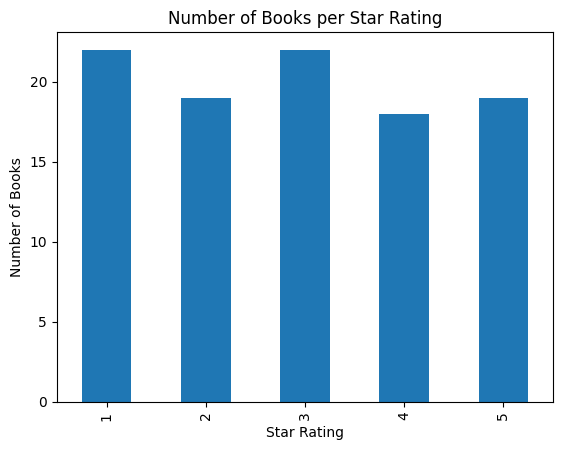

In [11]:
import matplotlib.pyplot as plt

counts = df["Rating"].value_counts().sort_index()
print(counts)

counts.plot(kind="bar", title="Number of Books per Star Rating")
plt.xlabel("Star Rating")
plt.ylabel("Number of Books")
plt.show()

In [12]:
df["Value"] = df["Rating"] / df["Price"]
sorted_df = df.sort_values("Value", ascending=False)

budget = 100
spent = 0
chosen = []

for _, row in sorted_df.iterrows():
    if spent + row["Price"] <= budget:
        chosen.append(row)
        spent += row["Price"]

chosen_df = pd.DataFrame(chosen)
print(chosen_df[["Title", "Price", "Rating"]])
print("\nTotal cost: £", round(spent, 2))
print("Total stars:", chosen_df["Rating"].sum())

                                                Title  Price  Rating
81   Princess Between Worlds (Wide-Awake Princess #5)  13.34       5
80  Princess Jellyfish 2-in-1 Omnibus, Vol. 01 (Pr...  13.61       5
34                                     Sophie's World  15.94       5
84                                           Patience  10.16       3
54                                             Thirst  17.27       5
12                                        Set Me Free  17.46       5

Total cost: £ 87.78
Total stars: 28


In [13]:
#Just for me to check
best6 = df[df["Rating"] == 5].nsmallest(6, "Price")
print(best6[["Title", "Price", "Rating"]])
print("Total cost: £", round(best6["Price"].sum(), 2))
print("Total stars:", best6["Rating"].sum())

                                                Title  Price  Rating
81   Princess Between Worlds (Wide-Awake Princess #5)  13.34       5
80  Princess Jellyfish 2-in-1 Omnibus, Vol. 01 (Pr...  13.61       5
34                                     Sophie's World  15.94       5
54                                             Thirst  17.27       5
12                                        Set Me Free  17.46       5
30  The Four Agreements: A Practical Guide to Pers...  17.66       5
Total cost: £ 95.28
Total stars: 30


CEO £100 Challenge Answer

First I tried a greedy method, picking books with the most stars per pound first. That gave 6 books for £87.78 and 28 stars, but one of them was Patience which is only 3 stars.

Then I checked the 6 cheapest 5-star books instead. That came to £95.28 and 30 stars, which is better and still under £100. So greedy was not the best answer here.

Final pick:
1. Princess Between Worlds - £13.34 - 5 stars
2. Princess Jellyfish 2-in-1 Omnibus Vol. 01 - £13.61 - 5 stars
3. Sophie's World - £15.94 - 5 stars
4. Thirst - £17.27 - 5 stars
5. Set Me Free - £17.46 - 5 stars
6. The Four Agreements - £17.66 - 5 stars

Total cost: £95.28
Total stars: 30

Business Recommendation

I would prioritize cheap 5-star books because only 19 out of 100 books have 5 stars, but the cheapest ones cost only £13-17 while the average book is £34.56. Customers get high quality for a low price, so these books are likely to sell well. The competitor has 100% of books in stock so we cannot beat them on availability, we should compete on lower prices instead.